# Задание 1: Q-learning, Q-learning + Dyna на детерминированной среде: S — пространство состояний дискретное, А — пространство действий дискретное.

In [1]:
import gymnasium as gym
import numpy as np
import random
import time
import matplotlib.pyplot as plt
from collections import defaultdict
from IPython.display import clear_output

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Настройки воспроизводимости
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Параметры среды и обучения
ENV_NAME = "Taxi-v3"
EPISODES = 300
ALPHA = 0.3          # Скорость обучения
GAMMA = 0.99         # Дисконтирование
EPSILON = 0.1        # Вероятность случайного действия
N_PLANNING = 50      # Количество шагов планирования для Dyna-Q

## Блок 1: Реализация Q-learning (Model-Free)

In [3]:
def run_q_learning():
    env = gym.make(ENV_NAME)
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    episode_rewards = []
    global_steps = []
    current_step = 0
    start_time = time.time()

    print("Запуск Q-learning...")

    for episode in range(EPISODES):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            # epsilon-greedy выбор действия
            if random.random() < EPSILON:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state])

            next_state, reward, done, truncated, _ = env.step(action)
            total_reward += reward
            current_step += 1

            # Обновление Q-функции
            best_next = np.max(Q[next_state])
            td_target = reward + GAMMA * best_next * (1 - done)
            Q[state][action] += ALPHA * (td_target - Q[state][action])

            state = next_state

        episode_rewards.append(total_reward)
        global_steps.append(current_step)

        if (episode + 1) % 50 == 0:
            avg_r = np.mean(episode_rewards[-50:])
            print(
                f"Episode {episode+1}/{EPISODES} | Avg Reward: {avg_r:.2f} | Steps: {current_step}")

    env.close()
    train_time = time.time() - start_time
    print(f"Q-learning завершен. Время: {train_time:.2f}s")
    return episode_rewards, global_steps, train_time

## Блок 2: Реализация Dyna-Q (Model-Based)

In [4]:
def run_dyna_q():
    env = gym.make(ENV_NAME)
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    model = defaultdict(dict)  # model[s][a] = (reward, next_state, done)

    episode_rewards = []
    global_steps = []
    current_step = 0
    start_time = time.time()

    print("Запуск Dyna-Q...")

    for episode in range(EPISODES):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            # epsilon-greedy
            if random.random() < EPSILON:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state])

            next_state, reward, done, truncated, _ = env.step(action)
            total_reward += reward
            current_step += 1

            # 1. Прямое обновление Q
            best_next = np.max(Q[next_state])
            td_target = reward + GAMMA * best_next * (1 - done)
            Q[state][action] += ALPHA * (td_target - Q[state][action])

            # 2. Обновление модели
            model[state][action] = (reward, next_state, done)

            # 3. Планирование (N_PLANNING шагов)
            for _ in range(N_PLANNING):
                # Случайный выбор из посещенных состояний
                if not model:
                    break
                m_state = random.choice(list(model.keys()))
                m_action = random.choice(list(model[m_state].keys()))
                m_reward, m_next, m_done = model[m_state][m_action]

                # Обновление Q на основе модели
                m_best_next = np.max(Q[m_next])
                m_td_target = m_reward + GAMMA * m_best_next * (1 - m_done)
                Q[m_state][m_action] += ALPHA * \
                    (m_td_target - Q[m_state][m_action])

            state = next_state

        episode_rewards.append(total_reward)
        global_steps.append(current_step)

        if (episode + 1) % 50 == 0:
            avg_r = np.mean(episode_rewards[-50:])
            print(
                f"Episode {episode+1}/{EPISODES} | Avg Reward: {avg_r:.2f} | Steps: {current_step}")

    env.close()
    train_time = time.time() - start_time
    print(f"Dyna-Q завершен. Время: {train_time:.2f}s")
    return episode_rewards, global_steps, train_time

## Блок 3: Запуск и визуализация

Запуск Q-learning...
Episode 50/300 | Avg Reward: -604.88 | Steps: 18352
Episode 100/300 | Avg Reward: -168.82 | Steps: 24864
Episode 150/300 | Avg Reward: -89.02 | Steps: 28727
Episode 200/300 | Avg Reward: -51.26 | Steps: 31305
Episode 250/300 | Avg Reward: -24.46 | Steps: 32930
Episode 300/300 | Avg Reward: -17.50 | Steps: 34324
Q-learning завершен. Время: 0.20s
Запуск Dyna-Q...
Episode 50/300 | Avg Reward: -226.42 | Steps: 5837
Episode 100/300 | Avg Reward: -4.46 | Steps: 6714
Episode 150/300 | Avg Reward: -0.06 | Steps: 7488
Episode 200/300 | Avg Reward: 2.64 | Steps: 8208
Episode 250/300 | Avg Reward: 0.06 | Steps: 9003
Episode 300/300 | Avg Reward: 0.50 | Steps: 9785
Dyna-Q завершен. Время: 1.26s


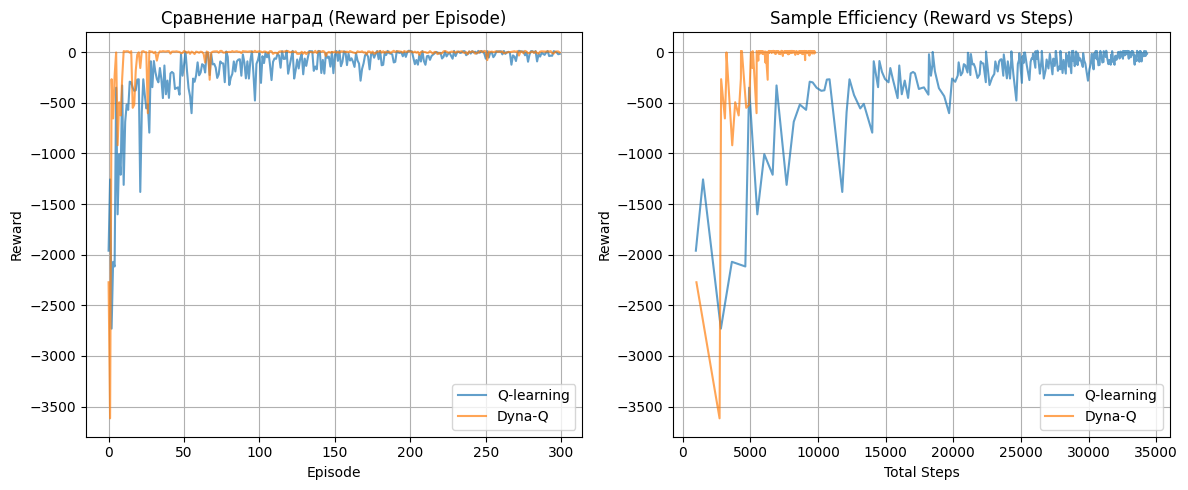


Итоги:
Q-learning:  Среднняя награда (посл. 50) = -17.50, Время = 0.20s
Dyna-Q:      Среднняя награда (посл. 50) = 0.50, Время = 1.26s
Dyna-Q должен сходиться быстрее по количеству шагов благодаря планированию.


In [6]:
# Запуск экспериментов
rewards_q, steps_q, time_q = run_q_learning()
rewards_dyna, steps_dyna, time_dyna = run_dyna_q()

# Визуализация
plt.figure(figsize=(12, 5))

# График наград
plt.subplot(1, 2, 1)
plt.plot(rewards_q, label='Q-learning', alpha=0.7)
plt.plot(rewards_dyna, label='Dyna-Q', alpha=0.7)
plt.title('Сравнение наград (Reward per Episode)')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.legend()
plt.grid(True)

# График сходимости
plt.subplot(1, 2, 2)
plt.plot(steps_q, rewards_q, label='Q-learning', alpha=0.7)
plt.plot(steps_dyna, rewards_dyna, label='Dyna-Q', alpha=0.7)
plt.title('Sample Efficiency (Reward vs Steps)')
plt.xlabel('Total Steps')
plt.ylabel('Reward')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"\nИтоги:")
print(
    f"Q-learning:  Среднняя награда (посл. 50) = {np.mean(rewards_q[-50:]):.2f}, Время = {time_q:.2f}s")
print(
    f"Dyna-Q:      Среднняя награда (посл. 50) = {np.mean(rewards_dyna[-50:]):.2f}, Время = {time_dyna:.2f}s")
print(f"Dyna-Q должен сходиться быстрее по количеству шагов благодаря планированию.")

---
# Задание 2. PPO, PPO + World Model на среде: S — пространство состояний непрерывное, А — пространство действий дискретное.

In [ ]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical, Normal
import random
import time
import matplotlib.pyplot as plt
from collections import defaultdict
from IPython.display import clear_output, HTML, display
from base64 import b64encode
# import imageio
# from pyvirtualdisplay import Display
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

In [ ]:
def make_env(env_id, idx):
    def thunk():
        env = gym.make(env_id)
        env = gym.wrappers.RecordEpisodeStatistics(env)
        return env
    return thunk

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

def record_video(env, policy, duration=1000):
    frames = []
    state, _ = env.reset()
    for _ in range(duration):
        action = policy(state)
        frame = env.render()
        frames.append(frame)
        state, _, terminated, truncated, _ = env.step(action)
        if terminated or truncated:
            break
    env.close()
    return frames

def show_progress(rewards_batch, log, step, global_steps, ax=None):
    if ax is None:
        clear_output(True)
        fig, ax = plt.subplots(figsize=(8,4))
    mean_reward = np.mean(rewards_batch)
    log.append(mean_reward)
    global_steps.append(step)
    ax.clear()
    ax.plot(global_steps, log, label='Mean reward')
    ax.legend()
    ax.grid(True)
    plt.pause(0.01)

In [ ]:
class WorldModel(nn.Module):
    """Модель мира: предсказывает reward, next_obs, done"""
    def __init__(self, obs_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            layer_init(nn.Linear(obs_dim + action_dim, 128)),
            nn.ReLU(),
            layer_init(nn.Linear(128, 128)),
            nn.ReLU(),
        )
        self.reward_net = layer_init(nn.Linear(128, 1), std=0.01)
        self.next_obs_net = layer_init(nn.Linear(128, obs_dim), std=0.01)
        self.done_net = nn.Sequential(
            layer_init(nn.Linear(128, 1), std=0.01),
            nn.Sigmoid()
        )

    def forward(self, obs, action):
        x = torch.cat([obs, action], dim=-1)
        x = self.net(x)
        reward = self.reward_net(x)
        next_obs = self.next_obs_net(x)
        done = self.done_net(x)
        return reward, next_obs, done

In [ ]:
class Agent(nn.Module):
    """Агент PPO (актёр + критика)"""
    def __init__(self, envs, continuous_action=False):
        super().__init__()
        self.continuous_action = continuous_action
        obs_shape = np.array(envs.single_observation_space.shape).prod()
        if continuous_action:
            self.action_dim = np.prod(envs.single_action_space.shape)
        else:
            self.action_dim = envs.single_action_space.n

        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_shape, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0),
        )
        if continuous_action:
            self.actor_mean = nn.Sequential(
                layer_init(nn.Linear(obs_shape, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, self.action_dim), std=0.01),
            )
            self.actor_logstd = nn.Parameter(torch.zeros(1, self.action_dim))
        else:
            self.actor = nn.Sequential(
                layer_init(nn.Linear(obs_shape, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, self.action_dim), std=0.01),
            )

    def get_value(self, x):
        return self.critic(x)

    def get_action_and_value(self, x, action=None, deterministic=False):
        if self.continuous_action:
            action_mean = self.actor_mean(x)
            action_logstd = self.actor_logstd.expand_as(action_mean)
            action_std = torch.exp(action_logstd)
            probs = Normal(action_mean, action_std)
            if action is None:
                action = probs.sample()
            return action, probs.log_prob(action).sum(1), probs.entropy().sum(1), self.critic(x)
        else:
            logits = self.actor(x)
            probs = Categorical(logits=logits)
            if action is None:
                action = probs.sample()
            return action, probs.log_prob(action), probs.entropy(), self.critic(x)

In [ ]:
class Args:
    """Гиперпараметры"""
    exp_name: str = "exp"
    seed: int = 1
    torch_deterministic: bool = True
    cuda: bool = True

    # PPO
    env_id: str = ""
    continuous_actions: bool = True
    total_timesteps: int = 2_000_000
    learning_rate: float = 3e-4
    num_envs: int = 8
    num_steps: int = 128
    anneal_lr: bool = True
    gamma: float = 0.99
    gae_lambda: float = 0.95
    num_minibatches: int = 4
    update_epochs: int = 4
    norm_adv: bool = True
    clip_coef: float = 0.2
    clip_vloss: bool = True
    ent_coef: float = 0.01
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5

    # World Model
    use_world_model: bool = True
    world_model_lr: float = 1e-3
    world_model_updates: int = 5
    imagination_batch_size: int = 64
    imagination_steps: int = 20
    img_update_epochs: int = 2

    def __post_init__(self):
        self.batch_size = self.num_envs * self.num_steps
        self.minibatch_size = self.batch_size // self.num_minibatches
        self.num_iterations = self.total_timesteps // self.batch_size
        assert self.imagination_batch_size % self.num_envs == 0

In [ ]:
def train(args):
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    torch.backends.cudnn.deterministic = args.torch_deterministic
    device = torch.device(
        "cuda" if torch.cuda.is_available() and args.cuda else "cpu")

    envs = gym.vector.SyncVectorEnv(
        [make_env(args.env_id, i) for i in range(args.num_envs)])
    agent = Agent(envs, continuous_action=args.continuous_actions).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=args.learning_rate, eps=1e-5)

    if args.use_world_model:
        obs_dim = np.array(envs.single_observation_space.shape).prod()
        action_dim = args.action_dim
        world_model = WorldModel(obs_dim, action_dim).to(device)
        world_optimizer = optim.Adam(
            world_model.parameters(), lr=args.world_model_lr)

    # Память для траекторий
    obs_mem = torch.zeros((args.num_steps, args.num_envs) +
                          envs.single_observation_space.shape).to(device)
    actions_mem = torch.zeros(
        (args.num_steps, args.num_envs) + envs.single_action_space.shape).to(device)
    logprobs_mem = torch.zeros((args.num_steps, args.num_envs)).to(device)
    rewards_mem = torch.zeros((args.num_steps, args.num_envs)).to(device)
    dones_mem = torch.zeros((args.num_steps, args.num_envs)).to(device)
    values_mem = torch.zeros((args.num_steps, args.num_envs)).to(device)

    global_step = 0
    start_time = time.time()
    next_obs, _ = envs.reset(seed=args.seed)
    next_obs = torch.Tensor(next_obs).to(device)
    next_done = torch.zeros(args.num_envs).to(device)

    episode_rewards = []
    log_rewards = []
    global_steps = []

    # Буфер для world model
    if args.use_world_model:
        wm_obs = []
        wm_actions = []
        wm_rewards = []
        wm_next_obs = []
        wm_dones = []

    for iteration in range(1, args.num_iterations + 1):
        if args.anneal_lr:
            frac = 1.0 - (iteration - 1.0) / args.num_iterations
            lrnow = frac * args.learning_rate
            optimizer.param_groups[0]['lr'] = lrnow

        # Сбор реальных данных
        for step in range(args.num_steps):
            global_step += args.num_envs
            obs_mem[step] = next_obs
            dones_mem[step] = next_done

            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(
                    next_obs)
                values_mem[step] = value.flatten()
            actions_mem[step] = action
            logprobs_mem[step] = logprob

            next_obs, reward, terminations, truncations, infos = envs.step(
                action.cpu().numpy())
            done_np = np.logical_or(terminations, truncations)
            rewards_mem[step] = torch.tensor(reward).to(device).view(-1)
            next_obs, next_done = torch.Tensor(next_obs).to(
                device), torch.Tensor(done_np).to(device)

            if args.use_world_model:
                # конвертируем actions для модели мира: для дискретных действий — one-hot
                if args.continuous_actions:
                    wm_act = action
                else:
                    wm_act = F.one_hot(
                        action.long(), num_classes=args.action_dim).float()
                wm_obs.append(next_obs.cpu())
                wm_actions.append(wm_act.cpu())
                wm_rewards.append(torch.tensor(reward).cpu())
                wm_next_obs.append(torch.Tensor(next_obs).cpu())
                wm_dones.append(torch.Tensor(done_np).cpu())

            if "episode" in infos:
                # Записываем среднюю награду по завершённым эпизодам
                mask = done_np.astype(bool)
                if mask.any():
                    ep_r = infos['episode']['r'][mask].mean()
                    episode_rewards.append(ep_r)

        # Обучение модели мира
        if args.use_world_model and iteration > 1:
            # Конвертируем списки в тензоры
            wm_obs_t = torch.cat(wm_obs, dim=0).to(device)
            wm_actions_t = torch.cat(wm_actions, dim=0).to(device)
            wm_rewards_t = torch.cat(wm_rewards, dim=0).to(device)
            wm_next_obs_t = torch.cat(wm_next_obs, dim=0).to(device)
            wm_dones_t = torch.cat(wm_dones, dim=0).to(device)
            dataset_size = wm_obs_t.shape[0]

            for _ in range(args.world_model_updates):
                idx = np.random.randint(
                    0, dataset_size, args.imagination_batch_size)
                batch_obs = wm_obs_t[idx].reshape(-1, obs_dim)
                batch_actions = wm_actions_t[idx].reshape(-1, action_dim)
                batch_rewards = wm_rewards_t[idx].reshape(-1, 1)
                batch_next_obs = wm_next_obs_t[idx].reshape(-1, obs_dim)
                batch_dones = wm_dones_t[idx].reshape(-1, 1)

                pred_rewards, pred_next_obs, pred_dones = world_model(
                    batch_obs, batch_actions)
                loss_reward = F.mse_loss(pred_rewards, batch_rewards)
                loss_obs = F.mse_loss(pred_next_obs, batch_next_obs)
                loss_done = F.binary_cross_entropy(pred_dones, batch_dones)
                loss_wm = loss_reward + loss_obs + loss_done

                world_optimizer.zero_grad()
                loss_wm.backward()
                world_optimizer.step()

        # Вычисление GAE и returns
        with torch.no_grad():
            next_value = agent.get_value(next_obs).reshape(1, -1)
            advantages = torch.zeros_like(rewards_mem)
            lastgaelam = 0
            for t in reversed(range(args.num_steps)):
                if t == args.num_steps - 1:
                    nextnonterminal = 1.0 - next_done
                    nextvalues = next_value
                else:
                    nextnonterminal = 1.0 - dones_mem[t + 1]
                    nextvalues = values_mem[t + 1]
                delta = rewards_mem[t] + args.gamma * \
                    nextvalues * nextnonterminal - values_mem[t]
                advantages[t] = lastgaelam = delta + args.gamma * \
                    args.gae_lambda * nextnonterminal * lastgaelam
            returns = advantages + values_mem

        # Сглаживаем батч
        b_obs = obs_mem.reshape((-1,) + envs.single_observation_space.shape)
        b_logprobs = logprobs_mem.reshape(-1)
        b_actions = actions_mem.reshape((-1,) + envs.single_action_space.shape)
        b_advantages = advantages.reshape(-1)
        b_returns = returns.reshape(-1)
        b_values = values_mem.reshape(-1)

        # PPO обновления на реальных данных
        b_inds = np.arange(args.batch_size)
        for epoch in range(args.update_epochs):
            np.random.shuffle(b_inds)
            for start in range(0, args.batch_size, args.minibatch_size):
                end = start + args.minibatch_size
                mb_inds = b_inds[start:end]

                _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                    b_obs[mb_inds], b_actions.long(
                    )[mb_inds] if not args.continuous_actions else b_actions[mb_inds]
                )

                logratio = newlogprob - b_logprobs[mb_inds]
                ratio = logratio.exp()

                mb_advantages = b_advantages[mb_inds]
                if args.norm_adv:
                    mb_advantages = (
                        mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)

                pg_loss1 = -mb_advantages * ratio
                pg_loss2 = -mb_advantages * \
                    torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
                pg_loss = torch.max(pg_loss1, pg_loss2).mean()

                newvalue = newvalue.view(-1)
                if args.clip_vloss:
                    v_loss_unclipped = (newvalue - b_returns[mb_inds]) ** 2
                    v_clipped = b_values[mb_inds] + torch.clamp(
                        newvalue - b_values[mb_inds], -args.clip_coef, args.clip_coef)
                    v_loss_clipped = (v_clipped - b_returns[mb_inds]) ** 2
                    v_loss = 0.5 * \
                        torch.max(v_loss_unclipped, v_loss_clipped).mean()
                else:
                    v_loss = 0.5 * \
                        ((newvalue - b_returns[mb_inds]) ** 2).mean()

                entropy_loss = entropy.mean()
                loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(
                    agent.parameters(), args.max_grad_norm)
                optimizer.step()

        # PPO в воображении
        if args.use_world_model and iteration > 5 and iteration % 2 == 0:
            for _ in range(args.imagination_steps):
                idx_start = np.random.randint(
                    0, dataset_size, args.imagination_batch_size)
                imag_obs = wm_obs_t[idx_start].reshape(-1, obs_dim)
                imag_logprobs = torch.zeros(
                    args.imagination_batch_size, device=device)
                imag_values = torch.zeros(
                    args.imagination_batch_size, device=device)
                imag_actions = torch.zeros(
                    args.imagination_batch_size, device=device).long()
                imag_rewards = torch.zeros(
                    args.imagination_batch_size, device=device)
                imag_dones = torch.zeros(
                    args.imagination_batch_size, device=device)

                with torch.no_grad():
                    imag_action, imag_logprob, _, imag_value = agent.get_action_and_value(
                        imag_obs)
                    if args.continuous_actions:
                        wm_act_input = imag_action
                        imag_actions = imag_action
                    else:
                        wm_act_input = F.one_hot(
                            imag_action.long(), num_classes=args.action_dim).float()
                        imag_actions = imag_action
                    imag_reward, imag_next_obs, imag_done = world_model(
                        imag_obs, wm_act_input)

                imag_done_flag = imag_done.squeeze() > 0.5
                if imag_done_flag.any():
                    reset_idx = np.random.randint(
                        0, dataset_size, size=imag_done_flag.sum())
                    imag_next_obs[imag_done_flag] = wm_obs_t[reset_idx].to(
                        device)

                with torch.no_grad():
                    imag_next_value = agent.get_value(imag_next_obs).squeeze(1)
                    imag_advantage = imag_reward.squeeze(
                        1) + args.gamma * imag_next_value * (1 - imag_done.squeeze(1)) - imag_value.squeeze(1)

                b_inds_img = np.arange(args.imagination_batch_size)
                for epoch in range(args.img_update_epochs):
                    np.random.shuffle(b_inds_img)
                    for start in range(0, args.imagination_batch_size, args.minibatch_size):
                        end = start + args.minibatch_size
                        mb_inds = b_inds_img[start:end]

                        if args.continuous_actions:
                            _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                                imag_obs[mb_inds], imag_actions[mb_inds])
                        else:
                            _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                                imag_obs[mb_inds], imag_actions[mb_inds].long())

                        logratio = newlogprob - imag_logprobs[mb_inds]
                        ratio = logratio.exp()
                        mb_advantages = imag_advantage[mb_inds]
                        if args.norm_adv:
                            mb_advantages = (
                                mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)
                        pg_loss1 = -mb_advantages * ratio
                        pg_loss2 = -mb_advantages * \
                            torch.clamp(ratio, 1 - args.clip_coef,
                                        1 + args.clip_coef)
                        pg_loss = torch.max(pg_loss1, pg_loss2).mean()

                        newvalue = newvalue.view(-1)
                        if args.clip_vloss:
                            v_loss_unclipped = (
                                newvalue - imag_next_value[mb_inds]) ** 2
                            v_clipped = imag_value[mb_inds] + torch.clamp(
                                newvalue - imag_value[mb_inds], -args.clip_coef, args.clip_coef)
                            v_loss_clipped = (
                                v_clipped - imag_next_value[mb_inds]) ** 2
                            v_loss = 0.5 * \
                                torch.max(v_loss_unclipped,
                                          v_loss_clipped).mean()
                        else:
                            v_loss = 0.5 * \
                                ((newvalue -
                                 imag_next_value[mb_inds]) ** 2).mean()

                        entropy_loss = entropy.mean()
                        loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef
                        optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(
                            agent.parameters(), args.max_grad_norm)
                        optimizer.step()

        if iteration % 5 == 0 and len(episode_rewards) > 0:
            log_rewards.append(np.mean(
                episode_rewards[-50:]) if len(episode_rewards) >= 50 else np.mean(episode_rewards))
            global_steps.append(global_step)
            clear_output(True)
            plt.figure(figsize=(10, 4))
            plt.plot(global_steps, log_rewards)
            plt.xlabel('Global steps')
            plt.ylabel('Average episode reward')
            plt.grid(True)
            plt.show()

    envs.close()
    return agent, episode_rewards, global_step

---
# Задание 3. PPO, PPO + World Model на среде: S — пространство состояний непрерывное, А — пространство действий непрерывное.